# DWLR Groundwater Evaluation — Spatial Analysis

This notebook investigates the geographic distribution of DWLR observations
and the spatial variation of Depth to Water Level (DTWL).

The analysis focuses on:

- Geographic coverage of DWLR observations
- Spatial distribution of DTWL
- State-level spatial patterns
- Identification of areas requiring further investigation
- Preparation for future location-based groundwater assessment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
DATA_FILE = Path("../data/processed/January_2026_clean.csv")

df = pd.read_csv(DATA_FILE)

df.head()

,STATE_UT,DISTRICT,BLOCK,VILLAGE,LATITUDE,LONGITUDE,DATE,DTWL
0,Andhra Pradesh,Alluri Sitharama Raju,Addateegala,Addateegala,17.4633,82.0271,2026-10-01,7.58
1,Andhra Pradesh,Alluri Sitharama Raju,Addateegala,Mallavaram Mammilu,17.5032,82.0124,2026-10-01,4.21
2,Andhra Pradesh,Alluri Sitharama Raju,Ananthagiri,Kottur,18.2074,83.0743,2026-10-01,3.73
3,Andhra Pradesh,Alluri Sitharama Raju,Araku Valley,Araku,18.3207,82.8814,2026-10-01,4.55
4,Andhra Pradesh,Alluri Sitharama Raju,Araku Valley,Aruku,18.3250,82.8793,2026-10-01,7.93


In [3]:
print("Number of observations:", len(df))
print("Unique coordinates:", df[["LATITUDE", "LONGITUDE"]].drop_duplicates().shape[0])

print("\nLatitude range:")
print(df["LATITUDE"].min(), "to", df["LATITUDE"].max())

print("\nLongitude range:")
print(df["LONGITUDE"].min(), "to", df["LONGITUDE"].max())

Number of observations: 16947
Unique coordinates: 16830

Latitude range:
8.08333 to 33.7693

Longitude range:
68.5203 to 96.13333


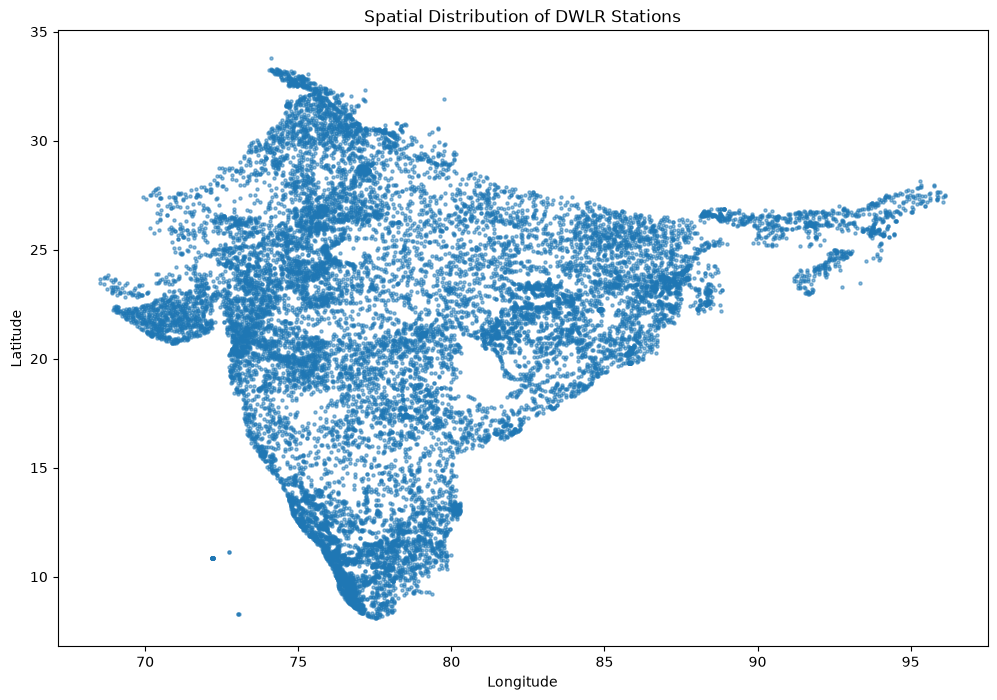

In [4]:
plt.figure(figsize=(12, 8))

plt.scatter(
    df["LONGITUDE"],
    df["LATITUDE"],
    s=5,
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of DWLR Stations")

plt.show()

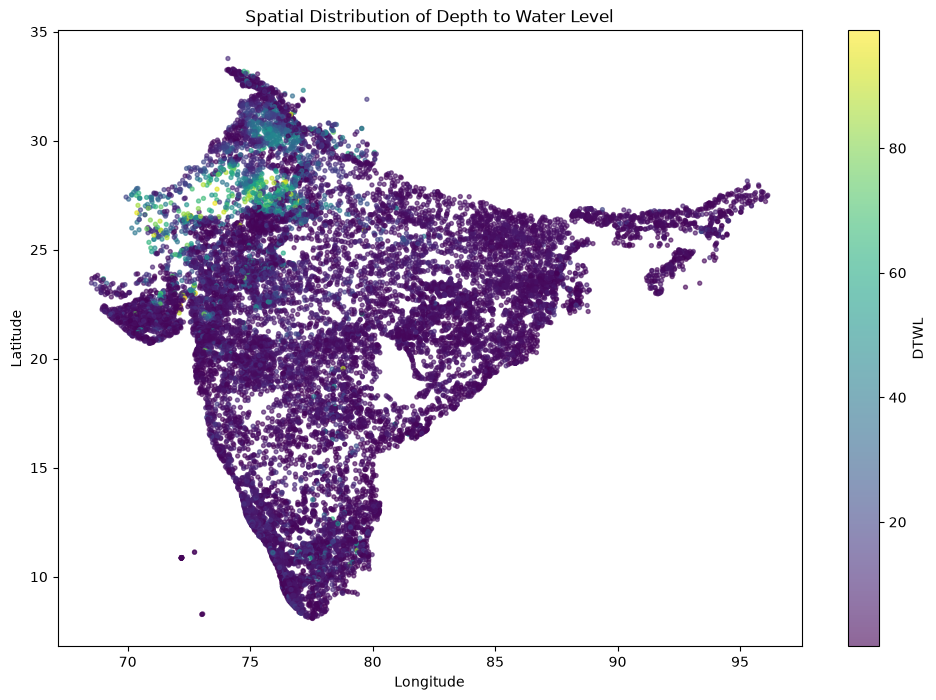

In [5]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df["LONGITUDE"],
    df["LATITUDE"],
    c=df["DTWL"],
    s=8,
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Depth to Water Level")

plt.colorbar(
    scatter,
    label="DTWL"
)

plt.show()

In [6]:
state_summary = (
    df.groupby("STATE_UT")
    .agg(
        observations=("DTWL", "count"),
        mean_dtwl=("DTWL", "mean"),
        median_dtwl=("DTWL", "median"),
        min_dtwl=("DTWL", "min"),
        max_dtwl=("DTWL", "max")
    )
    .sort_values("mean_dtwl", ascending=False)
)

state_summary

,observations,mean_dtwl,median_dtwl,min_dtwl,max_dtwl
STATE_UT,,,,,
Chandigarh,11,20.570000,17.050,2.85,48.61
Rajasthan,1953,20.209083,10.190,0.01,98.88
Punjab,534,19.294045,17.095,0.30,66.27
Haryana,257,17.745253,12.800,0.37,86.70
Uttarakhand,162,13.315123,8.610,0.01,76.31
Himachal Pradesh,117,11.147692,5.460,0.65,91.69
Delhi,89,10.405730,7.600,0.95,68.14
Jammu And Kashmir,172,9.446686,4.340,0.01,72.64
Madhya Pradesh,1243,7.753121,5.700,0.06,61.70


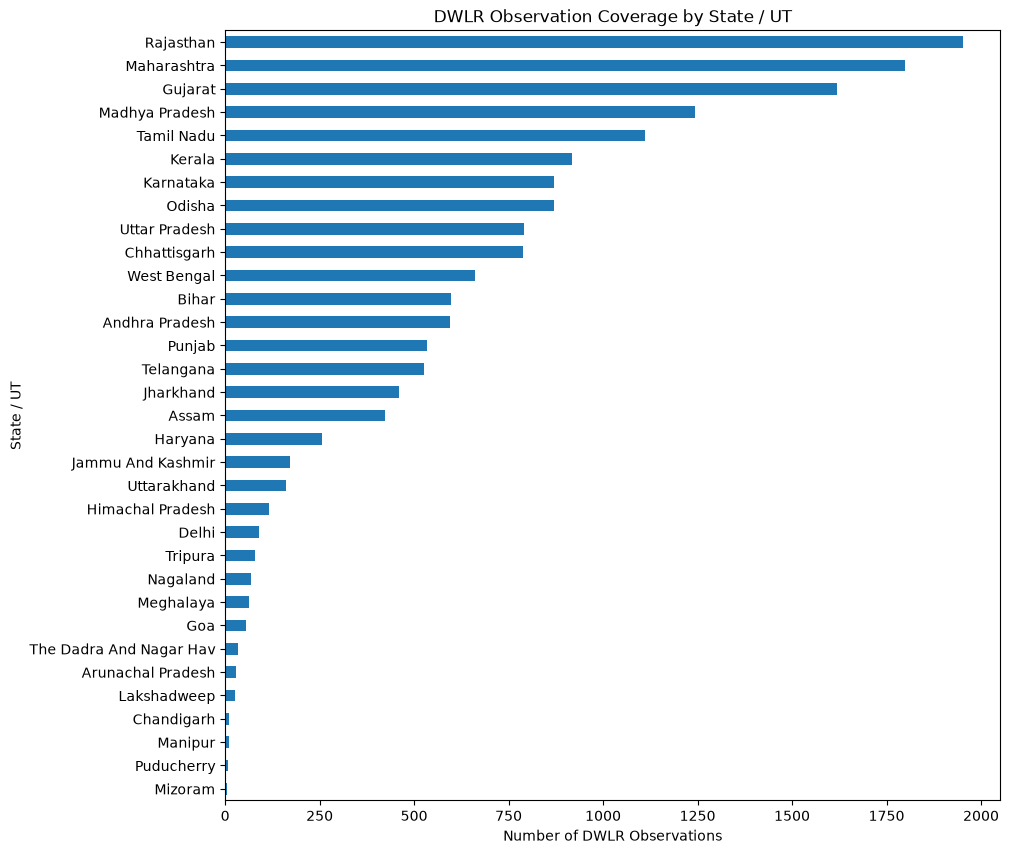

In [7]:
state_counts = (
    df["STATE_UT"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 10))

state_counts.plot(kind="barh")

plt.xlabel("Number of DWLR Observations")
plt.ylabel("State / UT")
plt.title("DWLR Observation Coverage by State / UT")

plt.show()

In [8]:
deepest = (
    df.sort_values("DTWL", ascending=False)
    [
        [
            "STATE_UT",
            "DISTRICT",
            "BLOCK",
            "VILLAGE",
            "LATITUDE",
            "LONGITUDE",
            "DTWL"
        ]
    ]
    .head(20)
)

deepest

,STATE_UT,DISTRICT,BLOCK,VILLAGE,LATITUDE,LONGITUDE,DTWL
13074,Rajasthan,Kotputli-Behror,Neemrana,Ghilot,28.06306,76.40694,98.88
13076,Rajasthan,Kotputli-Behror,Neemrana,Kanhawas,28.06250,76.36250,98.74
3201,Gujarat,Gandhinagar,Gandhinagar,Sadra,23.34769,72.73322,98.37
2621,Gujarat,Ahmedabad,NaN,NaN,22.77970,72.32610,98.13
12792,Rajasthan,Jodhpur (Gramin),Balesar,Navalgarh(Mcd-28),26.54390,72.56850,98.10
2628,Gujarat,Ahmedabad,NaN,NaN,22.44940,72.15420,98.10
11667,Rajasthan,Alwar,Kathumar,Salwari,27.21772,76.96161,96.68
13091,Rajasthan,Nagaur,Nagaur,Bishvani,27.12740,73.56120,96.67
2592,Gujarat,Ahmedabad,Daskroi,Kuha,23.00417,72.76500,96.54
15647,Uttar Pradesh,HAMIRPUR,NaN,NaN,25.90090,79.66490,95.61


In [9]:
shallowest = (
    df.sort_values("DTWL")
    [
        [
            "STATE_UT",
            "DISTRICT",
            "BLOCK",
            "VILLAGE",
            "LATITUDE",
            "LONGITUDE",
            "DTWL"
        ]
    ]
    .head(20)
)

shallowest

,STATE_UT,DISTRICT,BLOCK,VILLAGE,LATITUDE,LONGITUDE,DTWL
5783,Karnataka,Raichur,Sindhanur,Chikbergi,15.75830,76.50560,0.01
4743,Jammu And Kashmir,Udhampur,Udhampur,15Th Itbp,32.91470,75.07814,0.01
14949,Telangana,Nalgonda,Anumula,Madariguda,16.77100,79.22710,0.01
11934,Rajasthan,Bhilwara,Sahara,Koshithal,25.30770,74.18200,0.01
554,Andhra Pradesh,West Godavari,Palacole,Palakolu,16.50950,81.71940,0.01
9645,Maharashtra,Pune,Khed,Rajgurnagar (Khed),18.86389,73.89722,0.01
9658,Maharashtra,Pune,Mulshi,Mulshi,18.53250,73.51972,0.01
16235,Uttarakhand,Pauri Garhwal,Rikhnikhal,Rikhnikhal Road,29.83725,78.69978,0.01
16177,Uttarakhand,Dehradun,Vikasnagar,Jamuna Pull,30.51611,77.83556,0.01
16141,Uttarakhand,Dehradun,Doiwala,Bhaniawala,30.17778,78.13444,0.01


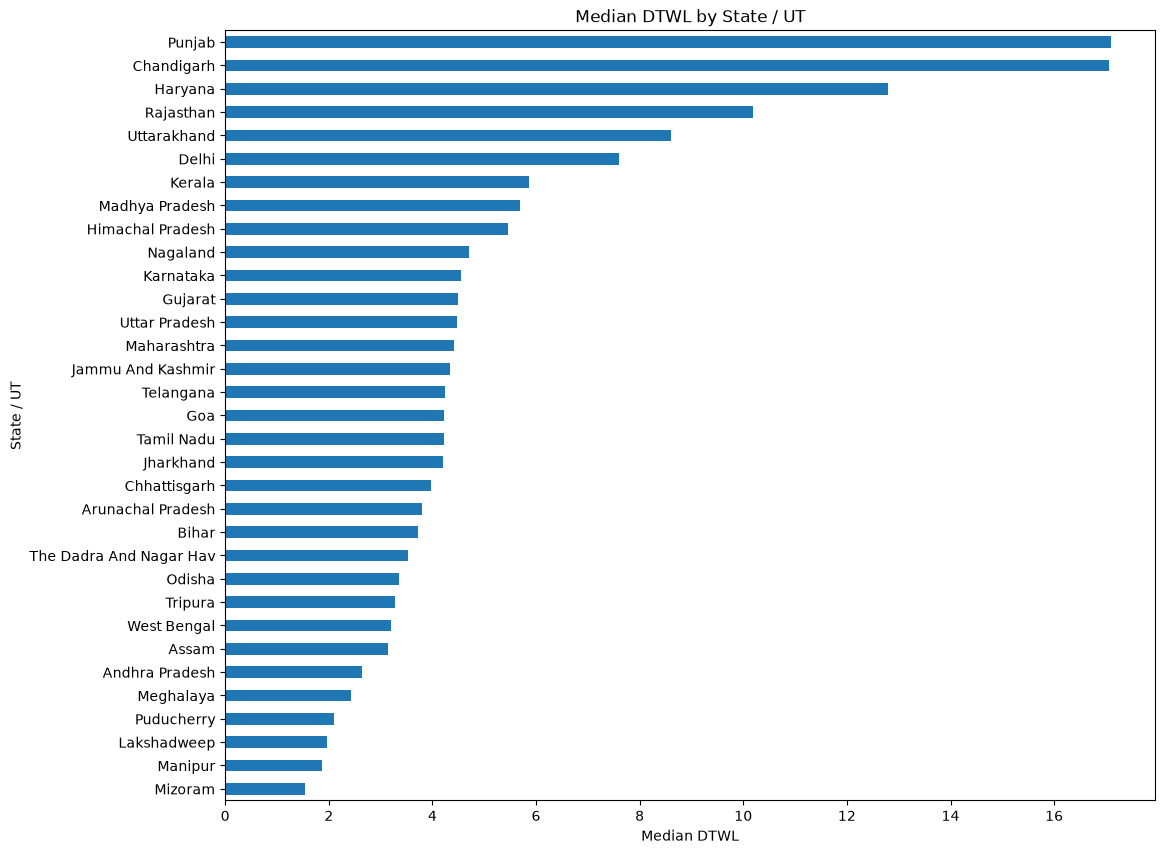

In [10]:
state_median = (
    df.groupby("STATE_UT")["DTWL"]
    .median()
    .sort_values()
)

plt.figure(figsize=(12, 10))

state_median.plot(kind="barh")

plt.xlabel("Median DTWL")
plt.ylabel("State / UT")
plt.title("Median DTWL by State / UT")

plt.show()

## Initial Spatial Observations

The DWLR dataset provides broad geographic coverage across multiple
States/UTs in India, although observation density is uneven.

The spatial DTWL visualization suggests geographic variation in measured
Depth to Water Level. However, the January 2026 dataset represents a
single-date snapshot and therefore cannot establish temporal groundwater
trends.

State-level comparisons should account for differences in observation
counts and should not be interpreted directly as groundwater availability
rankings.

Extreme DTWL observations are retained for further investigation rather
than being automatically classified as erroneous measurements.